# Run02

In [1]:
import tabpfn_client
from tabpfn_client import TabPFNRegressor, set_access_token
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
 
from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LassoCV, ElasticNetCV
from scipy.stats import pearsonr, spearmanr
 
API_TOKEN = "tabpfn_sk_68PLYl3C5VomK2RapEExGLt4g76XTcf0DKGyXpnPsME"
tabpfn_client.set_access_token(API_TOKEN)

In [2]:
# Load data
df = pd.read_csv(r"C:\Users\Pratham Shah\Downloads\Tubingen\Tabular_Models_Dataset\Updated01\community_index_v8_backup.csv")

print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("\nTarget (community_suppression) statistics:")
print(df['community_suppression'].describe().round(4))

print("\nRows per diversity level:")
print(df['diversity_level'].value_counts().sort_index())

print("\nRows per community size:")
print(df['community_size'].value_counts().sort_index())

Dataset shape: 30,000 rows × 168 columns

Target (community_suppression) statistics:
count    30000.0000
mean         0.6541
std          0.3209
min          0.0000
25%          0.4056
50%          0.7472
75%          0.9525
max          0.9990
Name: community_suppression, dtype: float64

Rows per diversity level:
diversity_level
1     6000
2     6000
4     6000
8     6000
16    6000
Name: count, dtype: int64

Rows per community size:
community_size
12    6000
16    6000
24    6000
32    6000
48    6000
Name: count, dtype: int64


In [3]:
species_cols = [f"Species_{i:04d}" for i in range(2, 102)]
r0_cols = [f"R0_c{k}" for k in range(1, 21)]
active_cols = [f"active_c{k}" for k in range(1, 21)]
structural_cols = ['community_size', 'diversity_level']
 
feature_cols = species_cols + r0_cols + active_cols + structural_cols
print(f"Total features: {len(feature_cols)}")
print(f"  Species membership:    {len(species_cols)}")
print(f"  R0 concentrations:     {len(r0_cols)}")
print(f"  Active flags:          {len(active_cols)}")
print(f"  Structural (size/div): {len(structural_cols)}")
 
X = df[feature_cols]
y = df['community_suppression']
 
print(f"\nX shape: {X.shape}    y shape: {y.shape}")
print(f"y range: [{y.min():.4f}, {y.max():.4f}]   mean: {y.mean():.4f}")

Total features: 142
  Species membership:    100
  R0 concentrations:     20
  Active flags:          20
  Structural (size/div): 2

X shape: (30000, 142)    y shape: (30000,)
y range: [0.0000, 0.9990]   mean: 0.6541


In [5]:
strat_key = df['community_size'].astype(str) + "_" + df['diversity_level'].astype(str)
 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=strat_key
)

groups = df['broth_id'].values
 
diversity_test = df.loc[X_test.index, 'diversity_level'].values
community_size_test = df.loc[X_test.index, 'community_size'].values
 
print(f"Train set: {X_train.shape[0]:,} rows")
print(f"Test set:  {X_test.shape[0]:,} rows")
print(f"Unique broths: {df['broth_id'].nunique()}")

Train set: 24,000 rows
Test set:  6,000 rows
Unique broths: 20


In [6]:
model = TabPFNRegressor(
    n_estimators=8,
    random_state=42,
)
model.fit(X_train, y_train)
 
predictions = model.predict(X_test)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)
 
print("TabPFN-3: Overall Test Set Performance")
print(f"  R2   : {r2:.4f}")
print(f"  MAE  : {mae:.4f}")
print(f"  RMSE : {rmse:.4f}")

00:07 Fitting... Done!
00:13 Predicting... Done!
TabPFN-3: Overall Test Set Performance
  R2   : 0.8995
  MAE  : 0.0555
  RMSE : 0.1027


In [7]:
results_df = pd.DataFrame({
    'y_true': y_test.values,
    'y_pred': predictions,
    'diversity_level': diversity_test,
    'community_size': community_size_test,
})
 
 
def condition_metrics(y_true_arr, y_pred_arr):
    # Takes the true and predicted values for one slice (e.g. all rows
    # with diversity_level == 4) and returns a dictionary of metrics.
    y_t = np.asarray(y_true_arr)
    y_p = np.asarray(y_pred_arr)
    r2_ = r2_score(y_t, y_p)
    mae_ = mean_absolute_error(y_t, y_p)
    rmse_ = np.sqrt(mean_squared_error(y_t, y_p))
    # pearsonr and spearmanr both return (correlation, p_value); we only
    # keep the correlation coefficient here, hence the "_" to discard
    # the p-value we don't need.
    pr, _ = pearsonr(y_t, y_p)
    sr, _ = spearmanr(y_t, y_p)
    bias = float(np.mean(y_p - y_t))
    std_true = float(np.std(y_t))
    # Normalised RMSE: dividing RMSE by the std of the true values in
    # this slice puts error on a comparable scale across slices that
    # have very different amounts of natural variation. A slice with
    # std_true near zero will have an unstable/huge nRMSE, which is
    # itself informative (it means R2 there can't be trusted).
    nrmse = rmse_ / std_true if std_true > 1e-8 else np.nan
    return {
        'n': len(y_t), 'r2': r2_, 'mae': mae_, 'rmse': rmse_,
        'pearson_r': pr, 'spearman_r': sr, 'bias': bias,
        'std_true': std_true, 'nrmse': nrmse,
    }
 
 
def reliability_flag(std_true):
    # A simple tiered flag: the lower the natural spread of true values
    # in a slice, the less trustworthy R2 is as a summary of that slice.
    if std_true < 0.05:
        return "LOW"
    elif std_true < 0.10:
        return "MED"
    return "OK"
 
 
hdr = (f"{'':6} {'R2':>7} {'MAE':>7} {'RMSE':>7} {'nRMSE':>7} "
       f"{'Pearson':>8} {'Spearman':>9} {'Bias':>8} {'std(y)':>7} "
       f"{'N':>6} {'Flag':>5}")
 
print("\nBy diversity level:")
print(hdr)
print("-" * len(hdr))
for d, grp in results_df.groupby('diversity_level'):
    m = condition_metrics(grp['y_true'], grp['y_pred'])
    flag = reliability_flag(m['std_true'])
    print(f"D={d:<3}  {m['r2']:>7.4f} {m['mae']:>7.4f} {m['rmse']:>7.4f} "
          f"{m['nrmse']:>7.4f} {m['pearson_r']:>8.4f} {m['spearman_r']:>9.4f} "
          f"{m['bias']:>8.4f} {m['std_true']:>7.4f} {m['n']:>6,} {flag:>5}")
print("Flag LOW/MED: std(y) is small in this slice, so R2 is unreliable "
      "here. Read MAE, nRMSE and Spearman r instead.")
 
print("\nBy community size:")
print(hdr)
print("-" * len(hdr))
for n, grp in results_df.groupby('community_size'):
    m = condition_metrics(grp['y_true'], grp['y_pred'])
    flag = reliability_flag(m['std_true'])
    print(f"N={n:<3}  {m['r2']:>7.4f} {m['mae']:>7.4f} {m['rmse']:>7.4f} "
          f"{m['nrmse']:>7.4f} {m['pearson_r']:>8.4f} {m['spearman_r']:>9.4f} "
          f"{m['bias']:>8.4f} {m['std_true']:>7.4f} {m['n']:>6,} {flag:>5}")


By diversity level:
            R2     MAE    RMSE   nRMSE  Pearson  Spearman     Bias  std(y)      N  Flag
---------------------------------------------------------------------------------------
D=1     0.9520  0.0435  0.0928  0.2192   0.9757    0.9271  -0.0035  0.4234  1,200    OK
D=2     0.7343  0.1019  0.1608  0.5155   0.8573    0.8987   0.0045  0.3120  1,200    OK
D=4     0.7747  0.0701  0.1082  0.4747   0.8817    0.9151   0.0006  0.2279  1,200    OK
D=8     0.9494  0.0365  0.0738  0.2249   0.9744    0.9784  -0.0029  0.3282  1,200    OK
D=16    0.9631  0.0256  0.0332  0.1921   0.9824    0.9815  -0.0072  0.1727  1,200    OK
Flag LOW/MED: std(y) is small in this slice, so R2 is unreliable here. Read MAE, nRMSE and Spearman r instead.

By community size:
            R2     MAE    RMSE   nRMSE  Pearson  Spearman     Bias  std(y)      N  Flag
---------------------------------------------------------------------------------------
N=12    0.7948  0.0967  0.1546  0.4530   0.8916    0.892

In [8]:
gkf = GroupKFold(n_splits=5)
 
oof_pred = np.full(len(X), np.nan)
fold_membership = np.full(len(X), -1)
 
print("\nGroupKFold evaluation (held-out broths):")
for fold_num, (tr_idx, te_idx) in enumerate(gkf.split(X, y, groups=groups), start=1):
    X_tr, y_tr = X.iloc[tr_idx], y.iloc[tr_idx]
    X_te = X.iloc[te_idx]
 
    held_broths = sorted(set(df.iloc[te_idx]['broth_id']))
    print(f"\nFold {fold_num}: broths={held_broths}  n_test={len(X_te):,}")
 
    m_fold = TabPFNRegressor(n_estimators=8, random_state=42)
    m_fold.fit(X_tr, y_tr)
    yp_fold = m_fold.predict(X_te)
 
    oof_pred[te_idx] = yp_fold
    fold_membership[te_idx] = fold_num
 
    r2_f = r2_score(y.iloc[te_idx], yp_fold)
    mae_f = mean_absolute_error(y.iloc[te_idx], yp_fold)
    rmse_f = np.sqrt(mean_squared_error(y.iloc[te_idx], yp_fold))
    print(f"  R2={r2_f:.4f}  MAE={mae_f:.4f}  RMSE={rmse_f:.4f}  (this fold's own metrics, for reference only)")
 
# Now pool all out-of-fold predictions together and compute one R2.
# This is the number we actually trust as the generalisation estimate.
valid_mask = ~np.isnan(oof_pred)
y_oof_true = y.values[valid_mask]
y_oof_pred = oof_pred[valid_mask]
 
r2_oof_pooled = r2_score(y_oof_true, y_oof_pred)
mae_oof_pooled = mean_absolute_error(y_oof_true, y_oof_pred)
rmse_oof_pooled = np.sqrt(mean_squared_error(y_oof_true, y_oof_pred))
 
print(f"\nPooled out-of-fold metrics across all {gkf.n_splits} folds (the honest generalisation estimate):")
print(f"  R2   = {r2_oof_pooled:.4f}")
print(f"  MAE  = {mae_oof_pooled:.4f}")
print(f"  RMSE = {rmse_oof_pooled:.4f}")
print(f"\nCompare to stratified-split R2={r2:.4f}")
print(f"Drop: {r2 - r2_oof_pooled:.4f}  (how much of the stratified-split score was broth memorisation)")


GroupKFold evaluation (held-out broths):

Fold 1: broths=['Broth_05', 'Broth_10', 'Broth_15', 'Broth_20']  n_test=6,000
00:10 Fitting... Done!
00:16 Predicting... Done!
  R2=0.3206  MAE=0.1552  RMSE=0.1855  (this fold's own metrics, for reference only)

Fold 2: broths=['Broth_04', 'Broth_09', 'Broth_14', 'Broth_19']  n_test=6,000
00:06 Fitting... Done!
00:18 Predicting... Done!
  R2=-0.2272  MAE=0.2528  RMSE=0.2919  (this fold's own metrics, for reference only)

Fold 3: broths=['Broth_03', 'Broth_08', 'Broth_13', 'Broth_18']  n_test=6,000
00:06 Fitting... Done!
00:12 Predicting... Done!
  R2=-1.9210  MAE=0.4043  RMSE=0.5190  (this fold's own metrics, for reference only)

Fold 4: broths=['Broth_02', 'Broth_07', 'Broth_12', 'Broth_17']  n_test=6,000
00:06 Fitting... Done!
00:12 Predicting... Done!
  R2=0.6147  MAE=0.1244  RMSE=0.1673  (this fold's own metrics, for reference only)

Fold 5: broths=['Broth_01', 'Broth_06', 'Broth_11', 'Broth_16']  n_test=6,000
00:06 Fitting... Done!
00:12 

In [9]:
seeds = [0, 1, 2, 3, 4]
stability_r2 = []
stability_mae = []
 
print("\nMulti-seed stability evaluation:")
for seed in seeds:
    Xtr_s, Xte_s, ytr_s, yte_s = train_test_split(
        X, y, test_size=0.20, random_state=seed, stratify=strat_key
    )
    m_seed = TabPFNRegressor(n_estimators=8, random_state=seed)
    m_seed.fit(Xtr_s, ytr_s)
    yp_seed = m_seed.predict(Xte_s)
 
    r2_seed = r2_score(yte_s, yp_seed)
    mae_seed = mean_absolute_error(yte_s, yp_seed)
    stability_r2.append(r2_seed)
    stability_mae.append(mae_seed)
    print(f"  seed={seed}:  R2={r2_seed:.4f}  MAE={mae_seed:.4f}")
 
print(f"\nAcross {len(seeds)} seeds:")
print(f"  R2:  mean={np.mean(stability_r2):.4f}  std={np.std(stability_r2):.4f}")
print(f"  MAE: mean={np.mean(stability_mae):.4f}  std={np.std(stability_mae):.4f}")


Multi-seed stability evaluation:
00:10 Fitting... Done!
00:15 Predicting... Done!
  seed=0:  R2=0.8932  MAE=0.0573
00:07 Fitting... Done!
00:13 Predicting... Done!
  seed=1:  R2=0.8998  MAE=0.0560
00:06 Fitting... Done!
00:13 Predicting... Done!
  seed=2:  R2=0.9008  MAE=0.0561
00:06 Fitting... Done!
00:13 Predicting... Done!
  seed=3:  R2=0.8951  MAE=0.0559
00:07 Fitting... Done!
00:13 Predicting... Done!
  seed=4:  R2=0.8921  MAE=0.0573

Across 5 seeds:
  R2:  mean=0.8962  std=0.0035
  MAE: mean=0.0565  std=0.0006


In [10]:

# Multi-seed GroupKFold evaluation (held-out broths, repeated)

# A single GroupKFold run only tells us about one particular way of
# dividing 20 broths into 5 groups of 4. Which broths happen to land
# together is itself a source of luck: one split might isolate the
# easiest broths together in one fold, another might isolate the
# hardest ones. To separate "real generalisation performance" from
# "this particular fold assignment was lucky/unlucky", we repeat the
# whole GroupKFold procedure several times with the broths shuffled
# into different fold assignments each time, and look at the spread.
#
# Note: sklearn's GroupKFold has no random_state parameter — by default
# it always assigns groups to folds in the same deterministic order.
# So to get different fold compositions per seed, we manually shuffle
# the order of the unique broth_ids before each run, then let GroupKFold
# split on that shuffled order.

n_seeds = 5
seed_list = [0, 1, 2, 3, 4]

unique_broths = df['broth_id'].unique()

seed_pooled_r2 = []
seed_pooled_mae = []
seed_pooled_rmse = []

print("Multi-seed GroupKFold evaluation (held-out broths):\n")

for seed in seed_list:
    # np.random.default_rng(seed): a random number generator seeded
    # reproducibly. .permutation() returns a shuffled copy of the array
    # without modifying the original.
    rng = np.random.default_rng(seed)
    shuffled_broths = rng.permutation(unique_broths)

    # Map each broth_id to a shuffled rank, then use that rank as the
    # "group" GroupKFold sees. This changes which broths get bundled
    # into the same fold together, without changing anything else.
    broth_rank = {b: i for i, b in enumerate(shuffled_broths)}
    shuffled_groups = df['broth_id'].map(broth_rank).values

    gkf = GroupKFold(n_splits=5)
    oof_pred = np.full(len(X), np.nan)

    for fold_num, (tr_idx, te_idx) in enumerate(
            gkf.split(X, y, groups=shuffled_groups), start=1):
        X_tr, y_tr = X.iloc[tr_idx], y.iloc[tr_idx]
        X_te = X.iloc[te_idx]

        m_fold = TabPFNRegressor(n_estimators=8, random_state=seed)
        m_fold.fit(X_tr, y_tr)
        oof_pred[te_idx] = m_fold.predict(X_te)

    # Pool this seed's 5 folds into one set of predictions before
    # scoring, for the same reason as the single-seed version: per-fold
    # R2 averaging is unstable when individual folds have low variance
    # in y_true.
    valid_mask = ~np.isnan(oof_pred)
    y_true_seed = y.values[valid_mask]
    y_pred_seed = oof_pred[valid_mask]

    r2_seed = r2_score(y_true_seed, y_pred_seed)
    mae_seed = mean_absolute_error(y_true_seed, y_pred_seed)
    rmse_seed = np.sqrt(mean_squared_error(y_true_seed, y_pred_seed))

    seed_pooled_r2.append(r2_seed)
    seed_pooled_mae.append(mae_seed)
    seed_pooled_rmse.append(rmse_seed)

    print(f"seed={seed}:  pooled R2={r2_seed:.4f}  MAE={mae_seed:.4f}  RMSE={rmse_seed:.4f}")

print(f"\nAcross {n_seeds} seeds (each seed = one full 5-fold pooled GroupKFold run):")
print(f"  R2:   mean={np.mean(seed_pooled_r2):.4f}  std={np.std(seed_pooled_r2):.4f}  "
      f"min={np.min(seed_pooled_r2):.4f}  max={np.max(seed_pooled_r2):.4f}")
print(f"  MAE:  mean={np.mean(seed_pooled_mae):.4f}  std={np.std(seed_pooled_mae):.4f}")
print(f"  RMSE: mean={np.mean(seed_pooled_rmse):.4f}  std={np.std(seed_pooled_rmse):.4f}")

print(f"\nFor reference, single stratified train/test split R2={r2:.4f}")
print(f"Mean generalisation drop across seeds: {r2 - np.mean(seed_pooled_r2):.4f}")
print("A large std here means the held-broth R2 from any single GroupKFold "
      "run should not be trusted on its own -- report the mean +/- std range instead.")

Multi-seed GroupKFold evaluation (held-out broths):

00:07 Fitting... Done!
00:13 Predicting... Done!
00:08 Fitting... Done!
00:12 Predicting... Done!
00:10 Fitting... Done!
00:14 Predicting... Done!
00:06 Fitting... Done!
00:13 Predicting... Done!
00:07 Fitting... Done!
00:12 Predicting... Done!
seed=0:  pooled R2=-0.1357  MAE=0.2726  RMSE=0.3419
00:07 Fitting... Done!
00:15 Predicting... Done!
00:10 Fitting... Done!
00:15 Predicting... Done!
00:08 Fitting... Done!
00:14 Predicting... Done!
00:06 Fitting... Done!
00:13 Predicting... Done!
00:12 Fitting... Done!
00:14 Predicting... Done!
seed=1:  pooled R2=0.0463  MAE=0.2339  RMSE=0.3133
00:06 Fitting... Done!
00:13 Predicting... Done!
00:06 Fitting... Done!
00:12 Predicting... Done!
00:06 Fitting... Done!
00:13 Predicting... Done!
00:07 Fitting... Done!
00:12 Predicting... Done!
00:06 Fitting... Done!
00:12 Predicting... Done!
seed=2:  pooled R2=0.1190  MAE=0.2351  RMSE=0.3012
00:07 Fitting... Done!
00:12 Predicting... Done!
00:06 Fit

Saved: tabpfn_0101_diagnostics.png


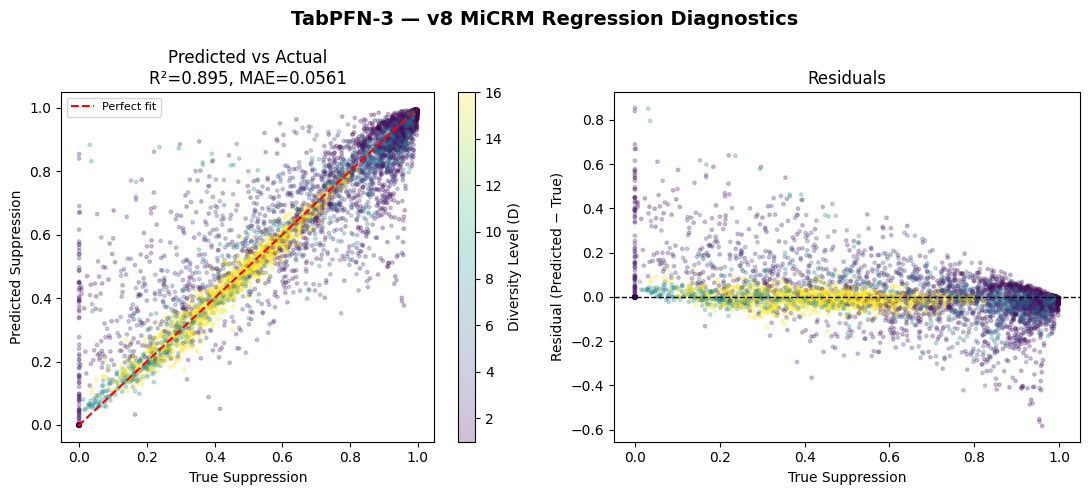

Saved: tabpfn_0101_diversity.png


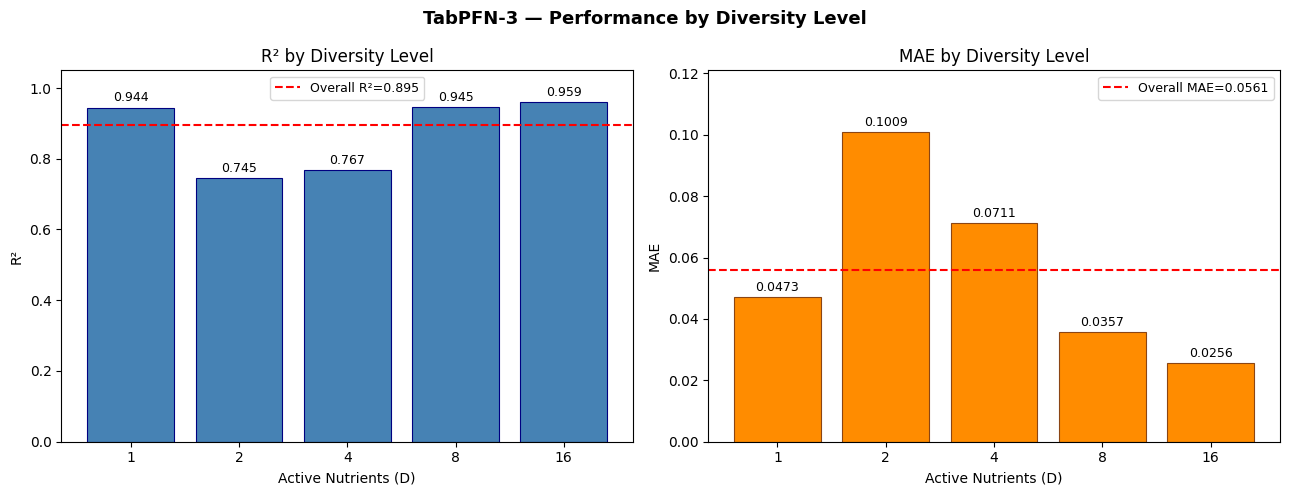

Saved: tabpfn_0101_community_size.png


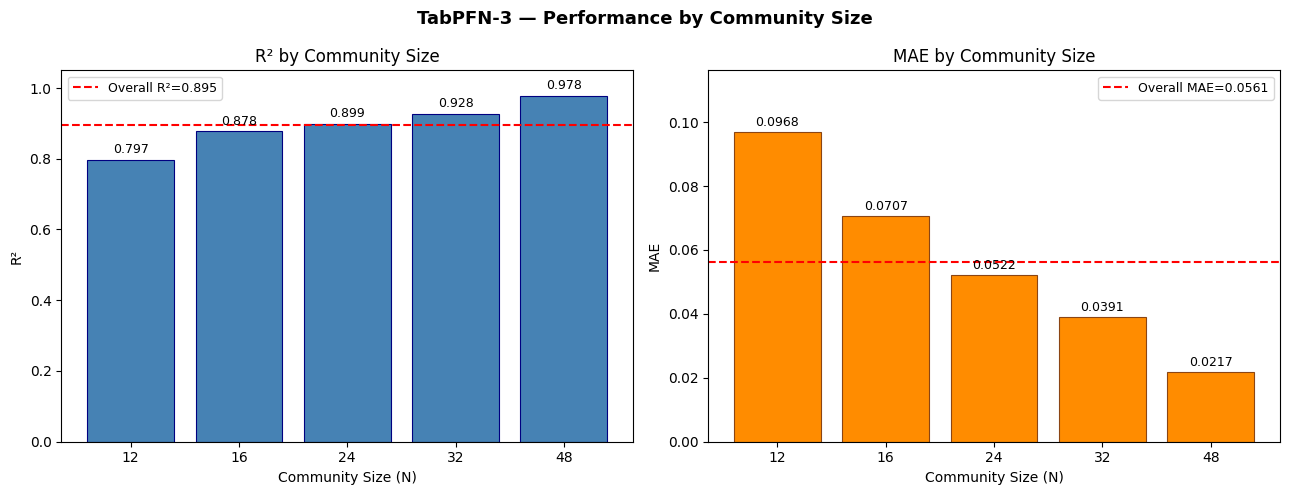

In [8]:
# figures

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
fig.suptitle("TabPFN-3 — v8 MiCRM Regression Diagnostics", fontsize=14, fontweight='bold')

# ── Panel 1: Predicted vs. Actual ─────────────────────────────────────────────
ax = axes[0]
sc = ax.scatter(y_test, predictions, alpha=0.25, s=6,
                c=diversity_test, cmap='viridis')
# c=diversity_test: colours each point by its diversity level
# cmap='viridis': maps low D to purple, high D to yellow

plt.colorbar(sc, ax=ax, label='Diversity Level (D)')
# colorbar(): adds a colour bar legend on the side of the plot
# ax=ax: attaches it to this specific subplot

lims = [min(y_test.min(), predictions.min()),
        max(y_test.max(), predictions.max())]
ax.plot(lims, lims, 'r--', lw=1.5, label='Perfect fit')
ax.set_xlabel("True Suppression")
ax.set_ylabel("Predicted Suppression")
ax.set_title(f"Predicted vs Actual\nR²={r2:.3f}, MAE={mae:.4f}")
ax.legend(fontsize=8)

# ── Panel 2: Residuals ────────────────────────────────────────────────────────
ax2 = axes[1]
residuals = predictions - y_test.values
# predictions is a NumPy array; y_test is a pandas Series.
# .values converts y_test to NumPy so subtraction is element-wise.

ax2.scatter(y_test, residuals, alpha=0.25, s=6,
            c=diversity_test, cmap='viridis')
ax2.axhline(0, color='black', lw=1, ls='--')
# axhline(0): horizontal reference line at zero error.
# Residuals scattered symmetrically around this = well-calibrated model.
ax2.set_xlabel("True Suppression")
ax2.set_ylabel("Residual (Predicted − True)")
ax2.set_title("Residuals")

plt.tight_layout()
plt.savefig("tabpfn_0101_diagnostics.png", dpi=150, bbox_inches='tight')
print("Saved: tabpfn_0101_diagnostics.png")
plt.show()

# =============================================================================
# ── SECTION 9: PER-DIVERSITY-LEVEL PLOTS ──────────────────────────────────────
# =============================================================================

diversity_levels = sorted(np.unique(diversity_test))
per_d_r2  = []
per_d_mae = []

for d in diversity_levels:
    mask   = (diversity_test == d)
    y_d    = y_test.values[mask]
    pred_d = predictions[mask]
    if len(y_d) < 5:
        per_d_r2.append(np.nan)
        per_d_mae.append(np.nan)
        continue
    per_d_r2.append(r2_score(y_d, pred_d))
    per_d_mae.append(mean_absolute_error(y_d, pred_d))

fig2, axes2 = plt.subplots(1, 2, figsize=(13, 5))
fig2.suptitle("TabPFN-3 — Performance by Diversity Level", fontsize=13, fontweight='bold')

d_labels = [str(int(d)) for d in diversity_levels]
# Converts diversity level integers to strings for x-axis tick labels

# ── Left: R² by diversity level ───────────────────────────────────────────────
ax_d_r2 = axes2[0]
bars_d_r2 = ax_d_r2.bar(d_labels, per_d_r2,
                          color='steelblue', edgecolor='navy', linewidth=0.8)
ax_d_r2.axhline(r2, color='red', ls='--', lw=1.5, label=f'Overall R²={r2:.3f}')
# Red dashed line at overall R² — shows which D levels pull performance up or down
ax_d_r2.set_xlabel("Active Nutrients (D)")
ax_d_r2.set_ylabel("R²")
ax_d_r2.set_title("R² by Diversity Level")
ax_d_r2.set_ylim(0, 1.05)
ax_d_r2.legend(fontsize=9)

for bar, val in zip(bars_d_r2, per_d_r2):
    if not np.isnan(val):
        ax_d_r2.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.01,
            f"{val:.3f}",
            ha='center', va='bottom', fontsize=9
        )

# ── Right: MAE by diversity level ─────────────────────────────────────────────
ax_d_mae = axes2[1]
bars_d_mae = ax_d_mae.bar(d_labels, per_d_mae,
                            color='darkorange', edgecolor='saddlebrown', linewidth=0.8)
ax_d_mae.axhline(mae, color='red', ls='--', lw=1.5, label=f'Overall MAE={mae:.4f}')
ax_d_mae.set_xlabel("Active Nutrients (D)")
ax_d_mae.set_ylabel("MAE")
ax_d_mae.set_title("MAE by Diversity Level")
ax_d_mae.set_ylim(0, max([v for v in per_d_mae if not np.isnan(v)]) * 1.2)
# max([v for v in per_d_mae if not np.isnan(v)]): finds the largest non-NaN MAE.
# The list comprehension filters out NaN values before taking the max,
# because max() would return NaN if any element is NaN.
# * 1.2 adds 20% headroom so bar annotations don't get clipped.
ax_d_mae.legend(fontsize=9)

for bar, val in zip(bars_d_mae, per_d_mae):
    if not np.isnan(val):
        ax_d_mae.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.001,
            f"{val:.4f}",
            ha='center', va='bottom', fontsize=9
        )

plt.tight_layout()
plt.savefig("tabpfn_0101_diversity.png", dpi=150, bbox_inches='tight')
print("Saved: tabpfn_0101_diversity.png")
plt.show()

# =============================================================================
# ── SECTION 10: PER-COMMUNITY-SIZE PLOTS ──────────────────────────────────────
# =============================================================================

community_size_test = df.loc[X_test.index, 'community_size'].values
# df.loc[X_test.index, 'community_size']: retrieves the community_size value
# for each test sample using its original row label in df.
# X_test.index holds those original labels even after the train/test split.

size_levels  = sorted(np.unique(community_size_test))
per_size_r2  = []
per_size_mae = []

for n in size_levels:
    mask   = (community_size_test == n)
    y_n    = y_test.values[mask]
    pred_n = predictions[mask]
    if len(y_n) < 5:
        per_size_r2.append(np.nan)
        per_size_mae.append(np.nan)
        continue
    per_size_r2.append(r2_score(y_n, pred_n))
    per_size_mae.append(mean_absolute_error(y_n, pred_n))

fig3, axes3 = plt.subplots(1, 2, figsize=(13, 5))
fig3.suptitle("TabPFN-3 — Performance by Community Size", fontsize=13, fontweight='bold')

size_labels = [str(int(n)) for n in size_levels]

# ── Left: R² by community size ────────────────────────────────────────────────
ax_s_r2 = axes3[0]
bars_s_r2 = ax_s_r2.bar(size_labels, per_size_r2,
                          color='steelblue', edgecolor='navy', linewidth=0.8)
ax_s_r2.axhline(r2, color='red', ls='--', lw=1.5, label=f'Overall R²={r2:.3f}')
ax_s_r2.set_xlabel("Community Size (N)")
ax_s_r2.set_ylabel("R²")
ax_s_r2.set_title("R² by Community Size")
ax_s_r2.set_ylim(0, 1.05)
ax_s_r2.legend(fontsize=9)

for bar, val in zip(bars_s_r2, per_size_r2):
    if not np.isnan(val):
        ax_s_r2.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.01,
            f"{val:.3f}",
            ha='center', va='bottom', fontsize=9
        )

# ── Right: MAE by community size ──────────────────────────────────────────────
ax_s_mae = axes3[1]
bars_s_mae = ax_s_mae.bar(size_labels, per_size_mae,
                            color='darkorange', edgecolor='saddlebrown', linewidth=0.8)
ax_s_mae.axhline(mae, color='red', ls='--', lw=1.5, label=f'Overall MAE={mae:.4f}')
ax_s_mae.set_xlabel("Community Size (N)")
ax_s_mae.set_ylabel("MAE")
ax_s_mae.set_title("MAE by Community Size")
ax_s_mae.set_ylim(0, max([v for v in per_size_mae if not np.isnan(v)]) * 1.2)
ax_s_mae.legend(fontsize=9)

for bar, val in zip(bars_s_mae, per_size_mae):
    if not np.isnan(val):
        ax_s_mae.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.001,
            f"{val:.4f}",
            ha='center', va='bottom', fontsize=9
        )

plt.tight_layout()
plt.savefig("tabpfn_0101_community_size.png", dpi=150, bbox_inches='tight')
print("Saved: tabpfn_0101_community_size.png")
plt.show()

In [ ]:
# =============================================================================
# ── SECTION 11: SHAP INTERPRETABILITY (cloud API compatible) ──────────────────
# =============================================================================
# SHAP answers: for each prediction, how much did each feature push the output
# up or down from the baseline (mean prediction)?
# Each SHAP value is a signed number:
#   positive → this feature pushed suppression HIGHER for this sample
#   negative → this feature pushed suppression LOWER for this sample
# The magnitude tells you how much, the sign tells you the direction.

import shap

print("\nComputing SHAP values (cloud API — may take a few minutes)...")

N_EXPLAIN = 30
# Number of test samples to explain.
# Each sample requires many masked .predict() calls to the Prior Labs API.
# Start with 30 to confirm it works, raise to 100 for final results.

feature_names = list(X_test.columns)
# X_test.columns: the column names of the DataFrame.
# list() converts it to a plain Python list for use in pd.DataFrame() later.

# Convert to NumPy BEFORE passing anything to SHAP.
# This prevents SHAP from stripping column names internally,
# which caused the "columns differ" error from the TabPFN API.
X_train_np   = X_train.values
# .values: converts a pandas DataFrame → NumPy array, shape (n_train, n_features).
# Column names are dropped — it becomes a plain numeric matrix.

X_explain_np = X_test.iloc[:N_EXPLAIN].values
# .iloc[:N_EXPLAIN]: select first N_EXPLAIN rows by integer position.
# .values: convert that DataFrame slice to a NumPy array.

background = shap.sample(X_train_np, 100, random_state=42)
# shap.sample(array, n, random_state): randomly picks n rows from the array.
# This background dataset represents the "average" input — when SHAP masks
# out a feature, it replaces it with values drawn from this background.
# 100 rows is standard; enough to represent the distribution, not too slow.

def predict_fn(X):
    # SHAP internally passes NumPy arrays to this function when computing
    # masked predictions. But TabPFN's cloud API checks that column names
    # match what it saw at .fit() time.
    # So we wrap model.predict() to restore column names before each call.
    return model.predict(pd.DataFrame(X, columns=feature_names))
    # pd.DataFrame(X, columns=feature_names):
    #   X       → the NumPy array SHAP constructed with some features masked
    #   columns → restores the original column names so TabPFN recognises them

explainer = shap.KernelExplainer(
    model=predict_fn,
    # We pass our wrapper function, not model.predict directly.
    # KernelExplainer will call predict_fn(masked_X) hundreds of times
    # per sample to estimate each feature's marginal contribution.

    data=background,
    # The background dataset used for marginalisation.
    # When feature j is "removed", its value is replaced by a draw from here.
)

shap_values = explainer.shap_values(
    X_explain_np,
    # The test samples to explain — NumPy array, shape (N_EXPLAIN, n_features).

    nsamples=256,
    # Number of masked coalitions evaluated per sample.
    # Higher → more accurate SHAP values but more API calls → slower.
    # 256 is a good starting point. Raise to 512 for final/report results.
)
# Returns NumPy array of shape (N_EXPLAIN, n_features).
# shap_values[i, j] = SHAP contribution of feature j to sample i's prediction.

print("SHAP computation complete.")

# =============================================================================
# ── SHAP Summary Bar Plot ─────────────────────────────────────────────────────
# Shows mean |SHAP| per feature — global importance across all explained samples.
# =============================================================================

plt.figure()
shap.summary_plot(
    shap_values,
    X_explain_np,
    feature_names=feature_names,
    max_display=20,
    # max_display=20: only show the 20 most important features.
    # With 142 features, showing all would be unreadable.
    show=False,
    # show=False: suppress plt.show() inside shap so we can save first.
    plot_type="bar",
    # plot_type="bar": horizontal bar chart of mean |SHAP| per feature.
)
plt.title("TabPFN-3 — Top 20 Features by Mean |SHAP|")
plt.tight_layout()
plt.savefig("tabpfn_shap_bar_0101.png", dpi=150, bbox_inches='tight')
print("Saved: tabpfn_shap_bar_0101.png")
plt.show()

# =============================================================================
# ── SHAP Beeswarm Plot ────────────────────────────────────────────────────────
# Shows the DISTRIBUTION of SHAP values across all explained samples.
# Each dot is one sample. Colour = feature value (red=high, blue=low).
# This tells you not just which features matter, but HOW they matter:
#   a feature with high value (red) pushing right → higher value → more suppression
#   a feature with high value (red) pushing left  → higher value → less suppression
# =============================================================================

plt.figure()
shap.summary_plot(
    shap_values,
    X_explain_np,
    feature_names=feature_names,
    max_display=20,
    show=False,
    # plot_type omitted → defaults to "dot" (beeswarm)
)
plt.title("TabPFN-3 — SHAP Beeswarm (Top 20 Features)")
plt.tight_layout()
plt.savefig("tabpfn_shap_beeswarm_0101.png", dpi=150, bbox_inches='tight')
print("Saved: tabpfn_shap_beeswarm_0101.png")
plt.show()


Computing SHAP values (cloud API — may take a few minutes)...
00:00 Predicting... -

00:09 Predicting... Done!


  0%|          | 0/30 [00:00<?, ?it/s]

00:00 Predicting... \

00:08 Predicting... Done!
00:20 Predicting... Done!
00:00 Predicting... \

...

00:08 Predicting... Done!
00:19 Predicting... Done!
00:00 Predicting... |

00:08 Predicting... Done!
00:19 Predicting... Done!
00:00 Predicting... \

00:08 Predicting... Done!
00:19 Predicting... Done!
00:00 Predicting... |

00:08 Predicting... Done!
00:18 Predicting... Done!
00:00 Predicting... |

00:08 Predicting... Done!
00:18 Predicting... Done!
00:12 Predicting... Done!
00:18 Predicting... Done!
00:12 Predicting... Done!
00:18 Predicting... Done!
00:09 Predicting... |